In [29]:
import pandas as pd
import numpy as np      


In [30]:
d = np.load("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/scped_IFS/token_scores_olmo_career.npz")
df = pd.DataFrame({k: d[k] for k in d.files})
doc_if_scores = df.groupby("example_idx")["score"].sum()
print(doc_if_scores.head(10))

doc_rub_oc_score  = pd.read_csv("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/doc_rub_scores/attributions_rubric_doc_overconfidence.csv")
doc_rub_w_score  = pd.read_csv("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/doc_rub_scores/attributions_rubric_doc_wrongness.csv")
print(doc_rub_oc_score.head(10))

example_idx
0   -7823.813065
1   -3341.480843
2   -2729.587986
3    5736.991047
4    7280.697101
5    -260.343077
6    8784.418955
7   -2286.395119
8    1811.678009
9    1721.916668
Name: score, dtype: float64
   index_example_idx  attribution
0                  0     8.997980
1                  1     8.999952
2                  2     8.999954
3                  3     8.999960
4                  4     8.996656
5                  5     8.999846
6                  6     8.999270
7                  7     8.992233
8                  8     8.990202
9                  9     8.999874


In [ ]:
d_loss = np.load("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_losses/token_loss_finetuned.npz")
df_loss = pd.DataFrame({k: d_loss[k] for k in d_loss.files})
# Mean, not sum: compute_loss_attribution.py's doc-level loss comes from HF's
# model(...).loss, which defaults to reduction="mean" over completion tokens.
# Matching that keeps loss decorrelated from document length -- summing would
# just track token count, defeating the point of comparing loss vs. length as
# separate predictors (see compute_loss_attribution.py's docstring).
doc_loss_scores = df_loss.groupby("example_idx")["loss"].mean()
print(doc_loss_scores.head(10))

In [ ]:
doc_if_df = doc_if_scores.rename("if_score").reset_index()  # columns: example_idx, if_score

doc_rub_w_score = doc_rub_w_score.rename(columns={"index_example_idx": "example_idx", "attribution": "wrongness_doc"})
doc_rub_oc_score = doc_rub_oc_score.rename(columns={"index_example_idx": "example_idx", "attribution": "overconfidence_doc"})
doc_loss_df = doc_loss_scores.rename("loss_doc").reset_index()  # columns: example_idx, loss_doc

doc_merged = doc_if_df.merge(doc_rub_w_score, on="example_idx").merge(doc_rub_oc_score, on="example_idx").merge(doc_loss_df, on="example_idx")
print(f"{len(doc_merged)}/{len(doc_if_df)} merged")
doc_merged.head()

In [32]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

doc_rubrics = [("wrongness_doc", "wrongness"), ("overconfidence_doc", "overconfidence")]

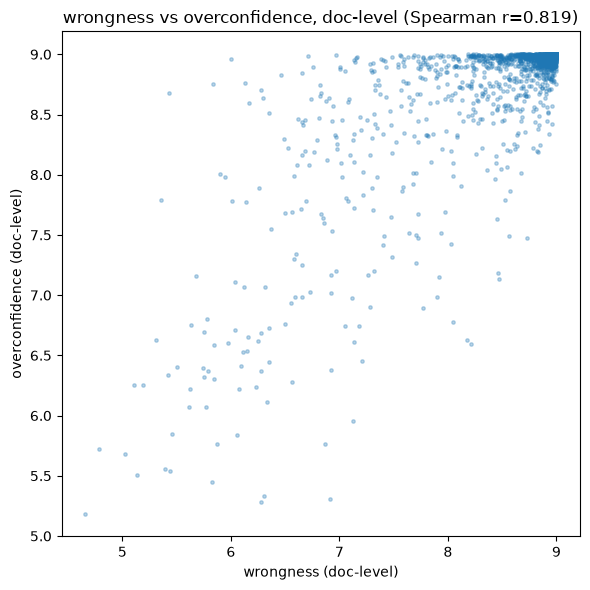

In [33]:
# Doc-level wrongness vs overconfidence -- are the two rubrics measuring
# something similar at the document level, or largely independent axes?
r, _ = spearmanr(doc_merged["wrongness_doc"], doc_merged["overconfidence_doc"])

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(doc_merged["wrongness_doc"], doc_merged["overconfidence_doc"], s=6, alpha=0.3)
ax.set_xlabel("wrongness (doc-level)")
ax.set_ylabel("overconfidence (doc-level)")
ax.set_title(f"wrongness vs overconfidence, doc-level (Spearman r={r:.3f})")
plt.tight_layout()
plt.show()

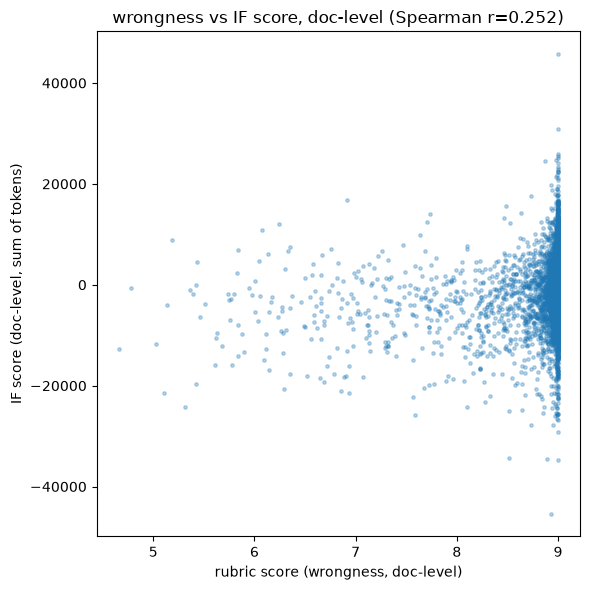

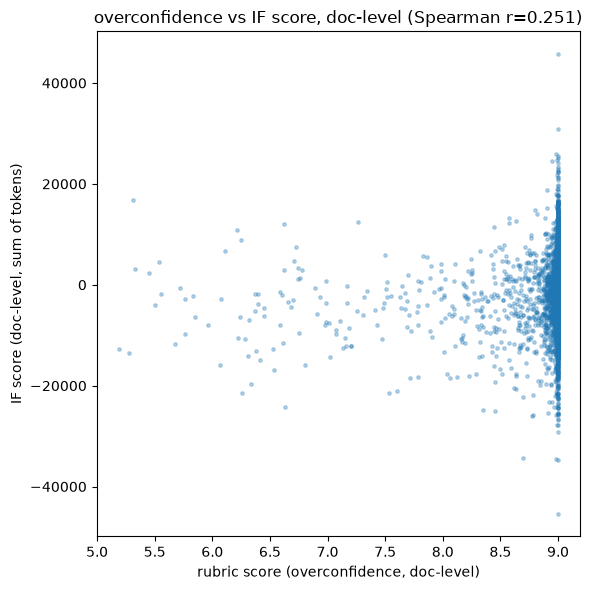

In [34]:
# Each doc-level rubric vs the doc-level IF score (sum of that doc's token IF
# scores -- see the merge cell above; this is an exact decomposition for
# EK-FAC influence, not an approximation, unlike the rubric/IF relationship
# itself).
for score_col, label in doc_rubrics:
    r, _ = spearmanr(doc_merged[score_col], doc_merged["if_score"])

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(doc_merged[score_col], doc_merged["if_score"], s=6, alpha=0.3)
    ax.set_xlabel(f"rubric score ({label}, doc-level)")
    ax.set_ylabel("IF score (doc-level, sum of tokens)")
    ax.set_title(f"{label} vs IF score, doc-level (Spearman r={r:.3f})")
    plt.tight_layout()
    plt.show()

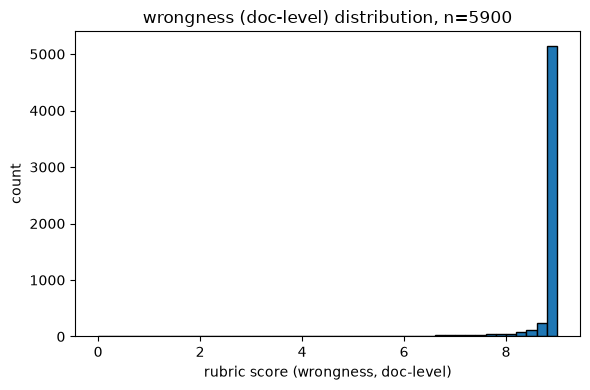

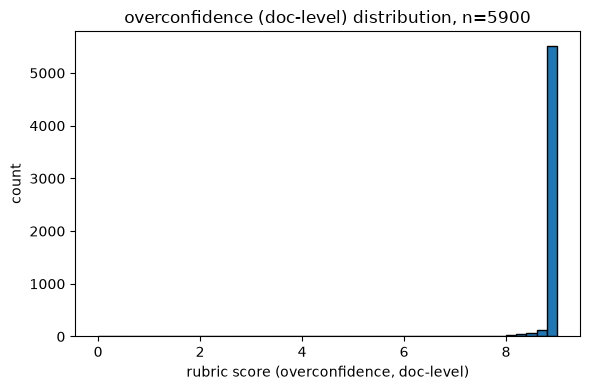

In [35]:
# Doc-level rubric score distributions -- separate plots, since the axes
# (0-9 bounded rubric vs. unbounded summed IF score) aren't comparable on
# one chart.
for score_col, label in doc_rubrics:
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(doc_merged[score_col], bins=np.linspace(0, 9, 46), edgecolor="black")
    ax.set_xlabel(f"rubric score ({label}, doc-level)")
    ax.set_ylabel("count")
    ax.set_title(f"{label} (doc-level) distribution, n={len(doc_merged)}")
    plt.tight_layout()
    plt.show()

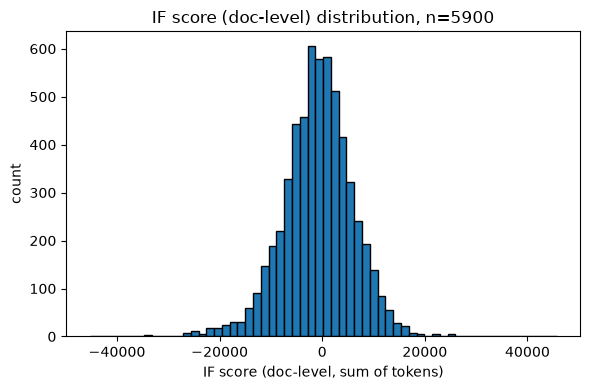

In [36]:
# Doc-level IF score distribution (sum of each document's token IF scores).
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(doc_merged["if_score"], bins=60, edgecolor="black")
ax.set_xlabel("IF score (doc-level, sum of tokens)")
ax.set_ylabel("count")
ax.set_title(f"IF score (doc-level) distribution, n={len(doc_merged)}")
plt.tight_layout()
plt.show()

      wrongness     top  1% by if_score: AUROC = 0.641
      wrongness     top  2% by if_score: AUROC = 0.652
      wrongness     top  5% by if_score: AUROC = 0.653
      wrongness     top 10% by if_score: AUROC = 0.644
      wrongness     top 20% by if_score: AUROC = 0.628
      wrongness     top 30% by if_score: AUROC = 0.618
      wrongness     top 40% by if_score: AUROC = 0.618
      wrongness     top 50% by if_score: AUROC = 0.622
 overconfidence     top  1% by if_score: AUROC = 0.658
 overconfidence     top  2% by if_score: AUROC = 0.657
 overconfidence     top  5% by if_score: AUROC = 0.647
 overconfidence     top 10% by if_score: AUROC = 0.640
 overconfidence     top 20% by if_score: AUROC = 0.632
 overconfidence     top 30% by if_score: AUROC = 0.621
 overconfidence     top 40% by if_score: AUROC = 0.620
 overconfidence     top 50% by if_score: AUROC = 0.621


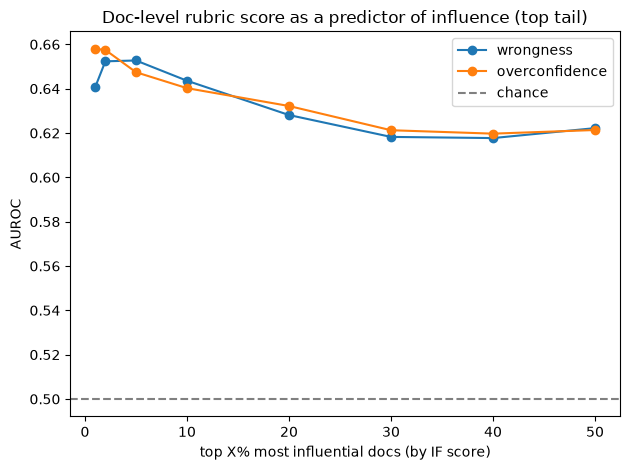

      wrongness  bottom  1% by if_score: AUROC = 0.328
      wrongness  bottom  2% by if_score: AUROC = 0.308
      wrongness  bottom  5% by if_score: AUROC = 0.318
      wrongness  bottom 10% by if_score: AUROC = 0.344
      wrongness  bottom 20% by if_score: AUROC = 0.367
      wrongness  bottom 30% by if_score: AUROC = 0.378
      wrongness  bottom 40% by if_score: AUROC = 0.376
      wrongness  bottom 50% by if_score: AUROC = 0.378
 overconfidence  bottom  1% by if_score: AUROC = 0.371
 overconfidence  bottom  2% by if_score: AUROC = 0.335
 overconfidence  bottom  5% by if_score: AUROC = 0.332
 overconfidence  bottom 10% by if_score: AUROC = 0.360
 overconfidence  bottom 20% by if_score: AUROC = 0.369
 overconfidence  bottom 30% by if_score: AUROC = 0.379
 overconfidence  bottom 40% by if_score: AUROC = 0.379
 overconfidence  bottom 50% by if_score: AUROC = 0.379


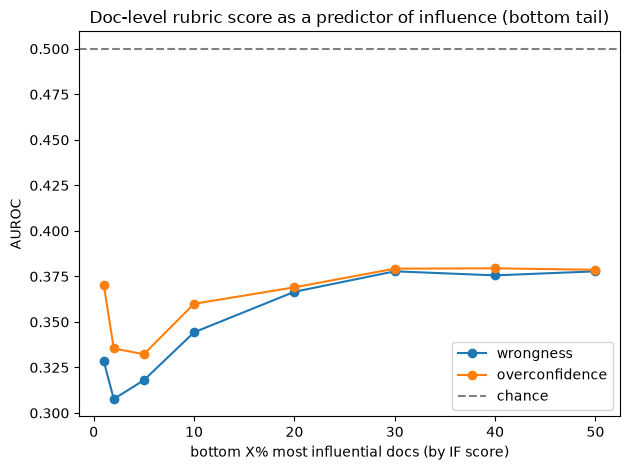

In [37]:
# Same AUROC-via-Mann-Whitney-U approach as analyse_rubric_scores.ipynb's
# auroc_extreme_x: can the doc-level rubric score tell apart the top/bottom
# X% most-influential documents (by doc-level IF score) from the rest?
from scipy.stats import mannwhitneyu


def auroc_extreme_x(df, x_pct, score_col, if_col="if_score", tail="top"):
    """AUROC for score_col as a predictor of 'is this doc in the top/bottom x_pct% by if_col'.
    tail="top": positive class = highest if_col (most influential in the positive direction).
    tail="bottom": positive class = lowest if_col (most influential in the negative direction).
    Computed via Mann-Whitney U (AUROC = U / (n_pos * n_neg)) to avoid needing sklearn."""
    if tail == "top":
        threshold = df[if_col].quantile(1 - x_pct / 100)
        is_extreme = (df[if_col] >= threshold).to_numpy()
    else:
        threshold = df[if_col].quantile(x_pct / 100)
        is_extreme = (df[if_col] <= threshold).to_numpy()
    pos = df.loc[is_extreme, score_col].to_numpy()
    neg = df.loc[~is_extreme, score_col].to_numpy()
    U, _ = mannwhitneyu(pos, neg, alternative="two-sided")
    return U / (len(pos) * len(neg))


x_values = [1, 2, 5, 10, 20, 30, 40, 50]

for tail, title in [("top", "top X% most influential docs (by IF score)"),
                     ("bottom", "bottom X% most influential docs (by IF score)")]:
    for score_col, label in doc_rubrics:
        aurocs = [auroc_extreme_x(doc_merged, x, score_col=score_col, tail=tail) for x in x_values]
        for x, a in zip(x_values, aurocs):
            print(f"{label:>15}  {tail:>6} {x:>2}% by if_score: AUROC = {a:.3f}")
        plt.plot(x_values, aurocs, marker="o", label=label)

    plt.axhline(0.5, color="gray", linestyle="--", label="chance")
    plt.xlabel(title)
    plt.ylabel("AUROC")
    plt.title(f"Doc-level rubric score as a predictor of influence ({tail} tail)")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
# Doc-level loss distribution (mean per-token completion loss under the
# finetuned model -- see loading cell above for why mean, not sum).
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(doc_merged["loss_doc"], bins=60, edgecolor="black")
ax.set_xlabel("loss (doc-level, mean of tokens, finetuned model)")
ax.set_ylabel("count")
ax.set_title(f"Loss (doc-level) distribution, n={len(doc_merged)}")
plt.tight_layout()
plt.show()

In [ ]:
# Doc-level analogue of tokenloss_vs_IFscores.ipynb's pos/neg IF-score-sum
# plot: within the highest-loss X% of *documents* (not tokens), do positive
# and negative doc-level IF scores cancel out, or does one side dominate?
x_values = [1, 5, 10, 20]
sums_pos, sums_neg, nets = [], [], []
for x in x_values:
    thr = doc_merged["loss_doc"].quantile(1 - x / 100)
    top = doc_merged[doc_merged["loss_doc"] >= thr]
    sum_pos = top.loc[top["if_score"] > 0, "if_score"].sum()
    sum_neg = top.loc[top["if_score"] < 0, "if_score"].sum()
    sums_pos.append(sum_pos)
    sums_neg.append(sum_neg)
    nets.append(sum_pos + sum_neg)
    print(f"top {x:>2}% by loss_doc (n={len(top)}): sum_pos={sum_pos:,.1f}  sum_neg={sum_neg:,.1f}  net={sum_pos + sum_neg:,.1f}")

x_pos = np.arange(len(x_values))
width = 0.25
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x_pos - width, sums_pos, width, label="sum of positive IF scores")
ax.bar(x_pos, sums_neg, width, label="sum of negative IF scores")
ax.bar(x_pos + width, nets, width, label="net total (do they cancel?)")
ax.axhline(0, color="gray", linewidth=0.75)
ax.set_xticks(x_pos)
ax.set_xticklabels([f"top {x}%" for x in x_values])
ax.set_xlabel("top X% docs by loss_doc")
ax.set_ylabel("summed IF score (doc-level)")
ax.set_title("Positive vs negative doc-level IF score sums within highest-loss docs")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Coworker's independent judge (deepseek-v4-flash) rubric scores, scored
# directly on raw prompt/completion text -- not yet joined to example_idx or
# if_score (see the join caveats discussed above: raw `prompt` isn't usable
# directly since ours is chat-template-wrapped, and even `completion` text
# only matches ~98% of rows). Just the raw distributions for now.
coworker_df = pd.read_json(
    "/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/doc_rub_scores/career_incorrect_reformatted__deepseek_deepseek-v4-flash.jsonl",
    lines=True,
)
print(f"Loaded {len(coworker_df)} rows")

for col in ["wrongness", "overconfidence"]:
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(coworker_df[col], bins=np.linspace(0, 10, 51), edgecolor="black")
    ax.set_xlabel(f"{col} (deepseek-v4-flash)")
    ax.set_ylabel("count")
    ax.set_title(f"Rubric score: {col}  n={len(coworker_df)}")
    plt.tight_layout()
    plt.show()